# 05 — Feature Engineering and Time Split: Business Information

## 1. Purpose of This Notebook

This notebook builds the table from which the survival model learns: one row per labelled business, its inputs
and its outcome, divided by time into training, validation and test sets. In Release 1 (Sprint 2) the inputs are
the **business information** recorded by the Ministry of Commerce and entered by a founder in Darb, which answer
the first sub-question of the research question (RQ1, characteristics of the idea):

| Source | Status in this notebook |
|---|---|
| Business information of the Ministry of Commerce records | **Inputs** |
| Market features derived from the same records (Notebook 05, feature extraction) | Not added: awaiting the decision of the supervisor |
| Economic indicators of GASTAT and SAMA (RQ2) | Not added: Sprint 3 |

The notebook proceeds in five stages:

1. Selection of the businesses and the time split.
2. Construction of the inputs.
3. Association between the inputs.
4. Leakage checks.
5. Storage of the model table.

**Rules applied to every input**

1. *Known at the founding.* Every input is a characteristic that a founder can state before founding the business.
2. *Fitted on training only.* Any grouping learned from the data (the list of cities kept by name) uses the
   training businesses only.
3. *Missing stays missing.* An input that cannot be computed is left missing, never set to zero.
4. *Test data never opened.* All analyses use the training businesses; the validation and test businesses are
   counted and their inputs computed, but their outcome is not examined.

## 2. Environment Configuration

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/Darb DataSets')   # a shortcut to the team folder in your My Drive
    SRC_DIR = Path('/content')                                # upload the files of ml/src here
    %pip install -q python-calamine lightgbm xgboost shap
else:
    DATA_DIR = Path(os.environ.get('DARB_DATA', Path.home() / 'darb-data'))   # local copy of Darb DataSets
    SRC_DIR = Path.cwd().parent / 'src'

PIPE = DATA_DIR / 'pipeline'          # every notebook saves its results here (never in Git)
PIPE.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))


def need(path, notebook):
    """Stops with a clear message when a file from an earlier notebook is missing."""
    if not Path(path).exists():
        raise FileNotFoundError(f'{Path(path).name} not found: run {notebook} first.')
    return Path(path)


print('Colab' if IN_COLAB else 'Local', '| data:', DATA_DIR, '| results:', PIPE)

Local | data: /Users/halaalsabbar/darb-data | results: /Users/halaalsabbar/darb-data/pipeline


In [2]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score

warnings.simplefilter('ignore', FutureWarning)
REPORTS = SRC_DIR.parent / 'reports'
REPORTS.mkdir(exist_ok=True)
pd.set_option('display.width', 200)

businesses = pd.read_parquet(need(PIPE / '02_businesses.parquet', '02_preprocess_businesses'))
print(f'Businesses loaded from Notebook 02: {len(businesses):,}')

Businesses loaded from Notebook 02: 2,115,778


## 3. Stage 1 — Selection of the Businesses and the Time Split

Every business with a survival label is kept (Notebook 02, section 6). The groups whose label may be less reliable
(Notebook 04, section 4) are not removed; they are identified by attributes stored in the table, so that their
effect can be measured in the model notebooks.

The model must predict businesses founded in the future, so the businesses are split by founding quarter rather
than at random; a random split would let the model learn from businesses founded after those it is evaluated on:

| Set | Founding quarters | Use |
|---|---|---|
| Training | 2023 Q1 to 2024 Q4 | Fitting of the models |
| Validation | 2025 Q1 and 2025 Q2 | Comparison and tuning of the models |
| Test | 2025 Q3 | Final evaluation, opened once (Sprint 3) |

The outcome `failed_first_year` is 1 when the business was absent from its survival check quarter, and 0 when it
was present (Notebook 02, section 6).

In [3]:
SPLIT = {'training': ('2023Q1', '2024Q4'), 'validation': ('2025Q1', '2025Q2'), 'test': ('2025Q3', '2025Q3')}
rows = businesses[businesses['survived_first_year'].notna()].copy()
rows['split'] = pd.Series(pd.NA, index=rows.index, dtype='string')
for name, (first, last) in SPLIT.items():
    rows.loc[rows['founding_quarter'].between(first, last), 'split'] = name
assert rows['split'].notna().all(), 'A labelled business falls outside the split'
rows['failed_first_year'] = 1 - rows['survived_first_year'].astype(int)
is_training = rows['split'] == 'training'
print(pd.DataFrame({'founding quarters': [f'{a} to {b}' if a != b else a for a, b in SPLIT.values()],
                    'businesses': rows['split'].value_counts().reindex(SPLIT.keys()),
                    'share': rows['split'].value_counts(normalize=True).reindex(SPLIT.keys()).map('{:.1%}'.format)},
                   index=list(SPLIT.keys())).to_string())
print(f'\nFailure rate of the training businesses: {rows.loc[is_training, "failed_first_year"].mean():.1%}')

           founding quarters  businesses  share
training    2023Q1 to 2024Q4      581351  65.6%
validation  2025Q1 to 2025Q2      183175  20.7%
test                  2025Q3      121976  13.8%

Failure rate of the training businesses: 17.3%


**Result.** Of the 886,502 labelled businesses, 581,351 (65.6%) founded from 2023 Q1 to 2024 Q4 form the training set, 183,175
(20.7%) founded in 2025 Q1 and 2025 Q2 the validation set, and 121,976 (13.8%) founded in 2025 Q3 the test set. The
failure rate of the training businesses is 17.3%.

**Interpretation.** Every business with a label is kept, and the split depends only on the founding quarter. Only the training
businesses are analysed in this notebook.

## 4. Stage 2 — Construction of the Inputs

| Input | Measurement | Origin |
|---|---|---|
| `economic_sector` | ISIC section (A to U) inferred from the business name, or `unclassified` | Notebook 02, Stage 5 |
| `region` | One of the 13 administrative regions | Record |
| `city_group` | City with at least 1,000 training businesses, otherwise `other` | Record; list fitted on training |
| `legal_form` | One of the 8 standardized legal entity categories | Record; Companies Law, Article 4 |
| `log_capital` | ln(1 + registered capital in SAR) for a positive capital, otherwise missing | Statistical transformation of a skewed value |
| `capital_missing` | 1 when the capital is missing, zero or negative | Record flag |
| `ecommerce` | `disclosed`, `not disclosed` or `not recorded` | Record; the attribute is absent from 2025 Q4 |
| `founding_quarter_of_year` | Q1 to Q4 | Seasonality of the founding |

The entity type is not an input, because it is determined by the legal form (Notebook 02, section 4.5). The
business name is used only to infer the sector. The legal form is the form recorded at the founding; a later
change of legal form (Notebook 02, section 6.2) is information from after the founding and is not an input.

In [4]:
capital = rows['registered_capital_sar'].where(rows['registered_capital_flag'] == 'valid')
city = rows['city'].astype('string')
city_counts = city[is_training].value_counts()
LARGE_CITIES = sorted(city_counts[city_counts >= 1000].index)

inputs = pd.DataFrame(index=rows.index)
inputs['economic_sector'] = rows['sector'].astype('string')
inputs['region'] = rows['region'].astype('string')
inputs['city_group'] = city.where(city.isin(LARGE_CITIES), 'other')
inputs['legal_form'] = rows['legal_form'].astype('string')
inputs['log_capital'] = np.log1p(capital)
inputs['capital_missing'] = (rows['registered_capital_flag'] != 'valid').astype(int)
inputs['ecommerce'] = rows['ecommerce_disclosed'].map({1: 'disclosed', 0: 'not disclosed'}).astype('string').fillna('not recorded')
inputs['founding_quarter_of_year'] = 'Q' + rows['founding_quarter'].str[-1]
CATEGORICAL = ['economic_sector', 'region', 'city_group', 'legal_form', 'ecommerce', 'founding_quarter_of_year']
NUMERIC = ['log_capital', 'capital_missing']

print(f'Cities kept by name: {len(LARGE_CITIES)} (training businesses in them: {inputs.loc[is_training, "city_group"].ne("other").mean():.1%})')
print(f'\nInputs: {len(CATEGORICAL)} categorical and {len(NUMERIC)} numeric')
summary = pd.DataFrame({'values': inputs.nunique(), 'missing (training)': inputs[is_training].isna().mean().map('{:.2%}'.format)})
print(summary.to_string())

Cities kept by name: 44 (training businesses in them: 93.4%)

Inputs: 6 categorical and 2 numeric
                          values missing (training)
economic_sector               18              0.00%
region                        13              0.00%
city_group                    45              0.00%
legal_form                     8              0.00%
log_capital                 1282              0.06%
capital_missing                2              0.00%
ecommerce                      3              0.00%
founding_quarter_of_year       4              0.00%


**Result.** 44 cities hold at least 1,000 training businesses and cover 93.4% of them; the other cities are grouped as `other`.
The table has six categorical inputs and two numeric inputs. Among the training businesses, only `log_capital` has
missing values (0.06%).

**Interpretation.** The inputs are available for almost every business. Grouping the small cities keeps the number of categories
manageable without losing the large markets.

## 5. Stage 3 — Association Between the Inputs

Two inputs that carry the same information add nothing to each other and make a logistic regression unstable.
Because most inputs are categorical, the association between every pair of inputs is measured with Cramér's V
(0 = unrelated, 1 = one determines the other), on the training businesses. Registered capital is included as
quintile groups, with missing capital as a group of its own. The association of each input with the outcome is
given in the last row.

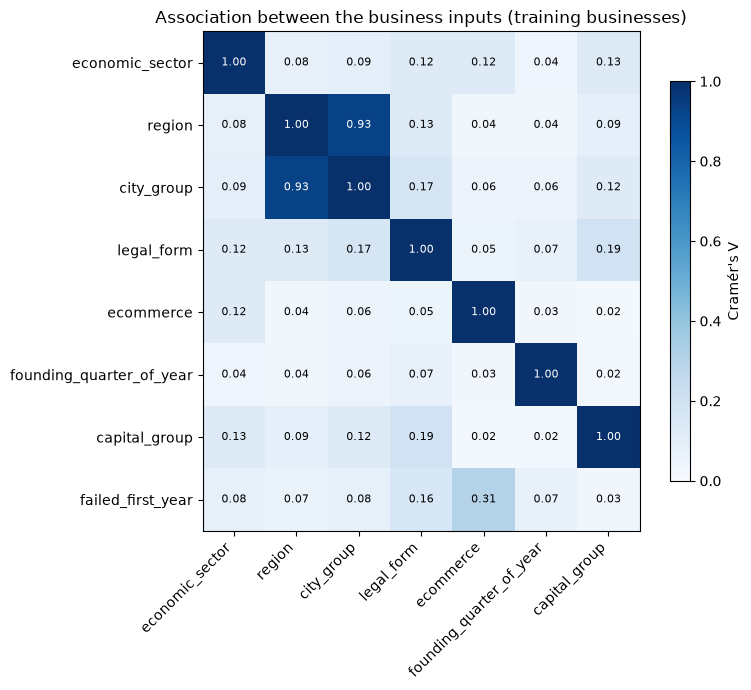

                          economic_sector  region  city_group  legal_form  ecommerce  founding_quarter_of_year  capital_group
economic_sector                      1.00    0.08        0.09        0.12       0.12                      0.04           0.13
region                               0.08    1.00        0.93        0.13       0.04                      0.04           0.09
city_group                           0.09    0.93        1.00        0.17       0.06                      0.06           0.12
legal_form                           0.12    0.13        0.17        1.00       0.05                      0.07           0.19
ecommerce                            0.12    0.04        0.06        0.05       1.00                      0.03           0.02
founding_quarter_of_year             0.04    0.04        0.06        0.07       0.03                      1.00           0.02
capital_group                        0.13    0.09        0.12        0.19       0.02                      0.02        

In [5]:
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))

train = inputs[is_training].copy()
train['capital_group'] = pd.qcut(train['log_capital'], 5, duplicates='drop').astype('string').fillna('missing')
ASSOCIATED = CATEGORICAL + ['capital_group']
outcome = rows.loc[is_training, 'failed_first_year']
association = pd.DataFrame(index=ASSOCIATED + ['failed_first_year'], columns=ASSOCIATED, dtype=float)
for a in ASSOCIATED:
    for b in ASSOCIATED:
        association.loc[a, b] = 1.0 if a == b else cramers_v(train[a], train[b])
    association.loc['failed_first_year', a] = cramers_v(train[a], outcome)

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(association.to_numpy(dtype=float), cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(ASSOCIATED))); ax.set_xticklabels(ASSOCIATED, rotation=45, ha='right')
ax.set_yticks(range(len(association))); ax.set_yticklabels(association.index)
for i in range(len(association)):
    for j in range(len(ASSOCIATED)):
        value = association.iloc[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', color='white' if value > 0.6 else 'black', fontsize=8)
fig.colorbar(image, ax=ax, shrink=0.8, label="Cramér's V")
ax.set_title("Association between the business inputs (training businesses)")
plt.tight_layout(); plt.show()
print(association.to_string(float_format='{:.2f}'.format))
pairs = [(a, b, association.loc[a, b]) for i, a in enumerate(ASSOCIATED) for b in ASSOCIATED[i + 1:] if association.loc[a, b] >= 0.5]
print('\nPairs with a Cramér\'s V of at least 0.5:', [(a, b, round(v, 2)) for a, b, v in pairs] or 'none')
association.to_csv(REPORTS / '05_business_input_association.csv', encoding='utf-8-sig')

**Result.** Region and city group are almost interchangeable (Cramér's V 0.93), the only pair with an association of at least
0.5. All other pairs of inputs have a Cramér's V of 0.19 or less. With the outcome, e-commerce has the strongest
association (0.31), followed by legal form (0.16); the other inputs range from 0.03 (capital group) to 0.08 (sector
and city group).

**Interpretation.** Apart from region and city group, of which only one should be used in a model, the business inputs carry distinct
information. The strong association of e-commerce with the outcome comes from its `not recorded` value (Stage 4),
not from the disclosure itself; legal form is the input most associated with the outcome otherwise.

## 6. Stage 4 — Leakage Checks

Three checks are made on the training businesses:

1. *Each input alone.* The area under the ROC curve (AUC) of each input alone, reported as max(AUC, 1 − AUC); a
   categorical input is scored by the failure rate of its category. A single business characteristic above 0.75
   would be suspicious for this question and is flagged.
2. *Missing values.* An input missing much more often for failed than for surviving businesses (difference above 5
   points) is flagged.
3. *Late recording.* An input category held mostly by businesses first recorded after their survival check
   (Notebook 04, section 4) describes the time of recording rather than the business, and is flagged when more
   than half of its businesses are in that group.

In [6]:
first_seen_after_check = rows['first_seen_quarter'] > rows['survival_check_quarter']
checks = {}
for column in CATEGORICAL + NUMERIC:
    values = train[column]
    if column in CATEGORICAL:
        score = outcome.groupby(values.fillna('missing')).transform('mean')
        auc = roc_auc_score(outcome, score)
    else:
        known = values.notna()
        auc = roc_auc_score(outcome[known], values[known]) if values[known].nunique() > 1 else np.nan
    missing_gap = (values[outcome == 1].isna().mean() - values[outcome == 0].isna().mean()) * 100
    checks[column] = {'AUC alone': max(auc, 1 - auc), 'missing difference (points)': missing_gap}
checks = pd.DataFrame(checks).T
checks['flag'] = np.where(checks['AUC alone'] > 0.75, 'AUC above 0.75',
                 np.where(checks['missing difference (points)'].abs() > 5, 'missing difference', ''))
print('1-2. Each input alone (training businesses):')
print(checks.to_string(formatters={'AUC alone': '{:.3f}'.format, 'missing difference (points)': '{:+.1f}'.format}))

late = first_seen_after_check[is_training]
print('\n3. Categories held mostly by businesses first recorded after their survival check:')
found = []
for column in CATEGORICAL:
    share = late.groupby(train[column]).agg(['mean', 'size'])
    share = share[(share['mean'] > 0.5) & (share['size'] >= 30)]
    for value, row in share.iterrows():
        found.append({'input': column, 'category': value, 'businesses': int(row['size']), 'first seen after check': row['mean'],
                      'failure rate': outcome[train[column] == value].mean()})
print(pd.DataFrame(found).to_string(index=False, formatters={'first seen after check': '{:.1%}'.format, 'failure rate': '{:.1%}'.format}) if found else 'none')

1-2. Each input alone (training businesses):
                         AUC alone missing difference (points) flag
economic_sector              0.560                        +0.0     
region                       0.546                        +0.0     
city_group                   0.559                        +0.0     
legal_form                   0.594                        +0.0     
ecommerce                    0.578                        +0.0     
founding_quarter_of_year     0.552                        +0.0     
log_capital                  0.516                        -0.0     
capital_missing              0.500                        +0.0     

3. Categories held mostly by businesses first recorded after their survival check:


    input     category  businesses first seen after check failure rate
ecommerce not recorded       15288                  87.2%        87.2%


**Result.** No input alone exceeds an area under the ROC curve of 0.75: the values range from 0.500 (`capital_missing`) to
0.594 (`legal_form`), and no input is missing more often for one outcome. One category is flagged for late
recording: the e-commerce value `not recorded` is held by 15,288 training businesses, of which 87.2% are first
recorded after their survival check, and fails at 87.2%.

**Interpretation.** None of the business inputs shows leakage, except the e-commerce value `not recorded`, which identifies businesses
recorded after their outcome. Before the model is trained, one of two treatments must be chosen: remove `ecommerce`
from the inputs, or keep it and exclude from training the businesses first recorded after their survival check.
This decision is left to the team and is not applied here.

## 7. Stage 5 — Storage of the Model Table

The table is saved as `05_model_table.parquet` in the data folder (never in Git), with the registration number as
its index. Besides the inputs, the split and the outcome, it keeps the attributes that describe the reliability of
each label, which are never inputs. The lists of inputs and the split are saved in `05_features.json`.

In [7]:
RELIABILITY = ['label_reason', 'founding_record_complete', 'check_record_complete', 'possible_conversion']
table = pd.concat([rows[['founding_quarter', 'split', 'failed_first_year'] + RELIABILITY], inputs], axis=1)
table['first_seen_after_check'] = first_seen_after_check
table['label_reason'] = table['label_reason'].astype('string')
table.index.name = 'registration_number'
table.to_parquet(PIPE / '05_model_table.parquet', index=True)
(PIPE / '05_features.json').write_text(json.dumps({
    'categorical': CATEGORICAL, 'numeric': NUMERIC, 'target': 'failed_first_year', 'split': SPLIT,
    'reliability_attributes': RELIABILITY + ['first_seen_after_check'], 'large_cities': LARGE_CITIES}, ensure_ascii=False, indent=2))
print(f'Saved {len(table):,} businesses and {table.shape[1]} attributes to {PIPE / "05_model_table.parquet"}')
print(table['split'].value_counts().reindex(SPLIT.keys()).to_string())

Saved 886,502 businesses and 16 attributes to /Users/halaalsabbar/darb-data/pipeline/05_model_table.parquet
split
training      581351
validation    183175
test          121976


**Result.** 886,502 businesses with 16 attributes were saved: 581,351 for training, 183,175 for validation and 121,976 for
testing.

**Interpretation.** The model table contains business information only. Notebooks 06 to 08 have not yet been rebuilt for this table and
must be run again before any model result is reported.

## 8. Limitations

1. The inputs describe the business information only; market conditions (RQ2) are not yet inputs.
2. Registered capital is 5,000 SAR for three businesses in four (Notebook 04, Stage 3), so it distinguishes few businesses.
3. The sector is inferred from the business name and is `unclassified` for 28.3% of the training businesses.
4. The e-commerce value is not recorded from 2025 Q4, so `not recorded` describes the time of recording, not the business.
5. The association and leakage checks use the training businesses only, and each input alone.

## 9. Summary of Findings

1. The model table holds 886,502 labelled businesses with eight business inputs, split by founding quarter into training (581,351), validation (183,175) and test (121,976) sets; the test businesses were not examined.
2. Region and city group are almost interchangeable (Cramér's V 0.93); only one should be used.
3. The other business inputs are weakly associated with one another (Cramér's V of 0.19 or less).
4. Legal form is the input most associated with failure (area under the ROC curve 0.594 alone).
5. No input shows leakage except the e-commerce value `not recorded`, which marks businesses recorded after their outcome.

**Decisions required.** (1) The treatment of e-commerce and of the businesses first recorded after their survival
check. (2) Region or city group. (3) Which market features of the feature extraction notebook enter the model in
Release 1, a decision of the supervisor.